## 1. Install dependencies

In [ ]:

!pip -q install kagglehub opencv-python-headless


In [ ]:
import os, io, time, random, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             balanced_accuracy_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cuda


## 2. Config



In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

IMG_SIZE = 224
BATCH_SIZE = 32
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
LR = 1e-4
NUM_WORKERS = 2

QUICK_MODE = True
SUBSET_PER_CLASS = 150 if QUICK_MODE else None
EPOCHS = 4 if QUICK_MODE else 15

MODEL_NAMES = ["ResNet101", "ResNet18", "DenseNet121"]
FILTER_NAMES = ["No Filter", "Average", "Gaussian", "Median", "Sharpening", "Sobel"]


## 3. Dataset preparation



In [ ]:
import kagglehub

ds_path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Dataset path:", ds_path)

meta_path = None
for root, dirs, files in os.walk(ds_path):
    for f in files:
        if f.lower() == "ham10000_metadata.csv":
            meta_path = os.path.join(root, f)
if meta_path is None:
    raise FileNotFoundError("Could not locate HAM10000_metadata.csv under the downloaded dataset.")

meta = pd.read_csv(meta_path)
print(meta.shape)
meta.head()


Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset path: /kaggle/input/skin-cancer-mnist-ham10000
(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [ ]:

image_paths = {}
for root, dirs, files in os.walk(ds_path):
    for f in files:
        if f.lower().endswith(".jpg"):
            image_paths[os.path.splitext(f)[0]] = os.path.join(root, f)

meta["path"] = meta["image_id"].map(image_paths)
meta = meta.dropna(subset=["path"]).reset_index(drop=True)
print("Images found on disk:", len(meta))

le = LabelEncoder()
meta["label"] = le.fit_transform(meta["dx"])
CLASSES = list(le.classes_)
NUM_CLASSES = len(CLASSES)
print("Classes:", CLASSES)


Images found on disk: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


/tmp/ipykernel_1733/2123582451.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=meta, x="dx", order=meta["dx"].value_counts().index, palette="viridis")


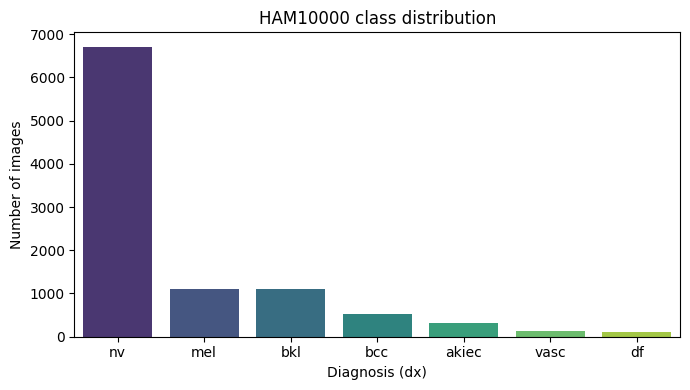

,count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115


In [ ]:

plt.figure(figsize=(7,4))
sns.countplot(data=meta, x="dx", order=meta["dx"].value_counts().index, palette="viridis")
plt.title("HAM10000 class distribution")
plt.xlabel("Diagnosis (dx)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

meta["dx"].value_counts()


In [ ]:

if SUBSET_PER_CLASS is not None:
    meta = (meta.groupby("dx", group_keys=False)
                 .apply(lambda g: g.sample(min(len(g), SUBSET_PER_CLASS), random_state=SEED)))
    meta = meta.reset_index(drop=True)
    print("Using subset of", len(meta), "images (QUICK_MODE)")

train_df, temp_df = train_test_split(meta, test_size=VAL_SPLIT + TEST_SPLIT,
                                      stratify=meta["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_SPLIT / (VAL_SPLIT + TEST_SPLIT),
                                    stratify=temp_df["label"], random_state=SEED)
print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))


Using subset of 1007 images (QUICK_MODE)
Train: 704 Val: 151 Test: 152


/tmp/ipykernel_1733/3867340729.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), SUBSET_PER_CLASS), random_state=SEED)))


## 4. Image filtering



In [ ]:
def apply_filter(img_np, filter_name):
    """img_np: HxWx3 uint8 RGB array. Returns HxWx3 uint8 RGB array."""
    if filter_name == "No Filter":
        return img_np
    elif filter_name == "Average":
        return cv2.blur(img_np, (5, 5))
    elif filter_name == "Gaussian":
        return cv2.GaussianBlur(img_np, (5, 5), 0)
    elif filter_name == "Median":
        return cv2.medianBlur(img_np, 5)
    elif filter_name == "Sharpening":
        kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
        return cv2.filter2D(img_np, -1, kernel)
    elif filter_name == "Sobel":
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        mag = np.sqrt(gx ** 2 + gy ** 2)
        mag = np.uint8(255 * mag / (mag.max() + 1e-8))
        return np.stack([mag, mag, mag], axis=-1)
    else:
        raise ValueError(filter_name)


class FilterTransform:
    """torchvision-compatible transform: PIL Image -> filtered PIL Image."""
    def __init__(self, filter_name):
        self.filter_name = filter_name

    def __call__(self, pil_img):
        arr = np.array(pil_img.convert("RGB"))
        filtered = apply_filter(arr, self.filter_name)
        return Image.fromarray(filtered)


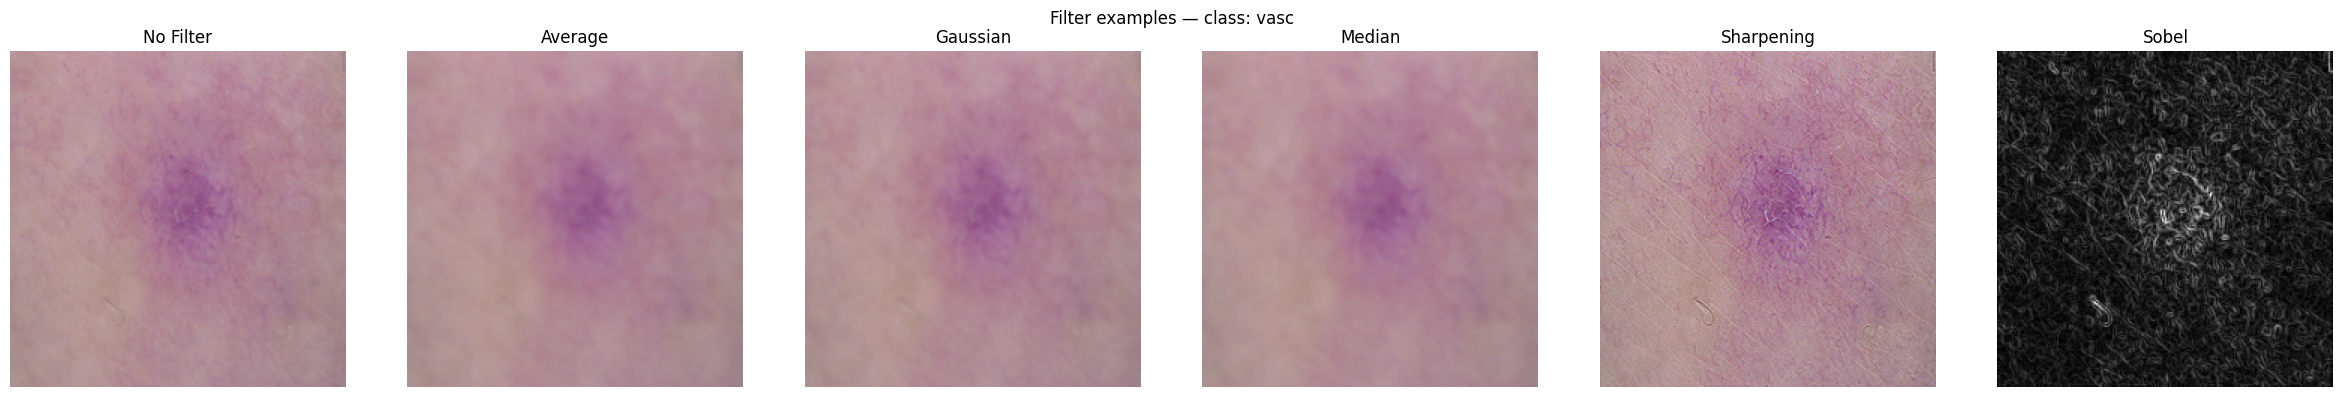

In [ ]:

sample_row = meta.sample(1, random_state=SEED).iloc[0]
sample_img = Image.open(sample_row["path"]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))

fig, axes = plt.subplots(1, len(FILTER_NAMES), figsize=(4 * len(FILTER_NAMES), 4))
for ax, fname in zip(axes, FILTER_NAMES):
    filtered = FilterTransform(fname)(sample_img)
    ax.imshow(filtered)
    ax.set_title(fname)
    ax.axis("off")
plt.suptitle(f"Filter examples — class: {sample_row['dx']}")
plt.tight_layout()
plt.savefig("filter_examples.png", dpi=150)
plt.show()


## 5. Dataset class + dataloader builder

In [ ]:
class HAM10000Dataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["path"]).convert("RGB")
        img = self.transform(img)
        return img, int(row["label"])


NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

def make_transforms(filter_name, train):
    ops = [transforms.Resize((IMG_SIZE, IMG_SIZE))]
    if train:
        ops += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(15)]
    ops += [FilterTransform(filter_name), transforms.ToTensor(),
            transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)]
    return transforms.Compose(ops)

def make_loaders(filter_name):
    train_ds = HAM10000Dataset(train_df, make_transforms(filter_name, train=True))
    val_ds = HAM10000Dataset(val_df, make_transforms(filter_name, train=False))
    test_ds = HAM10000Dataset(test_df, make_transforms(filter_name, train=False))
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader, test_loader


## 6. Model loading — the 3 best backbones from Task 01

In [ ]:
def build_model(name, num_classes):
    if name == "ResNet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "ResNet101":
        m = models.resnet101(weights=models.ResNet101_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "DenseNet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    else:
        raise ValueError(name)
    return m


## 7. Training + evaluation utilities

In [ ]:
def train_one_model(model, train_loader, val_loader, epochs, lr, device):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    best_state, best_val_acc = None, -1
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)
        train_loss, train_acc = run_loss / total, correct / total

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                loss = criterion(out, yb)
                v_loss += loss.item() * xb.size(0)
                v_correct += (out.argmax(1) == yb).sum().item()
                v_total += yb.size(0)
        val_loss, val_acc = v_loss / v_total, v_correct / v_total

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc); history["val_acc"].append(val_acc)
        print(f"  epoch {epoch+1}/{epochs}  train_acc={train_acc:.4f}  val_acc={val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, history


@torch.no_grad()
def evaluate(model, loader, device, num_classes):
    model.eval()
    all_probs, all_preds, all_labels = [], [], []
    for xb, yb in loader:
        xb = xb.to(device)
        out = model(xb)
        probs = F.softmax(out, dim=1).cpu().numpy()
        all_probs.append(probs)
        all_preds.append(probs.argmax(1))
        all_labels.append(yb.numpy())
    probs = np.concatenate(all_probs)
    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)

    metrics = {
        "Accuracy": accuracy_score(labels, preds) * 100,
        "Precision": precision_score(labels, preds, average="macro", zero_division=0) * 100,
        "Recall": recall_score(labels, preds, average="macro", zero_division=0) * 100,
        "F1-score": f1_score(labels, preds, average="macro", zero_division=0) * 100,
        "Macro-F1": f1_score(labels, preds, average="macro", zero_division=0) * 100,
        "Balanced Accuracy": balanced_accuracy_score(labels, preds) * 100,
    }
    try:
        metrics["AUC"] = roc_auc_score(labels, probs, multi_class="ovr", average="macro") * 100
    except ValueError:
        metrics["AUC"] = np.nan

    cm = confusion_matrix(labels, preds)
    report = classification_report(labels, preds, target_names=CLASSES,
                                    output_dict=True, zero_division=0)
    return metrics, cm, report, (labels, preds, probs)


## 8. Run all experiments: 3 models × (baseline + 5 filters) = 18 runs

Same split, same preprocessing besides the filter, same training settings for every run.
Results, histories, confusion matrices and reports are all kept for the visualization and
comparative-analysis sections below.


In [ ]:
all_results = []
all_histories = {}
all_confusions = {}
all_reports = {}

for model_name in MODEL_NAMES:
    for filter_name in FILTER_NAMES:
        print(f"\n=== {model_name} | {filter_name} ===")
        train_loader, val_loader, test_loader = make_loaders(filter_name)
        model = build_model(model_name, NUM_CLASSES)
        model, history = train_one_model(model, train_loader, val_loader, EPOCHS, LR, DEVICE)
        metrics, cm, report, _ = evaluate(model, test_loader, DEVICE, NUM_CLASSES)
        print(f"{model_name} | {filter_name}: {metrics}")

        all_results.append({"Model": model_name, "Filter": filter_name, **metrics})
        all_histories[(model_name, filter_name)] = history
        all_confusions[(model_name, filter_name)] = cm
        all_reports[(model_name, filter_name)] = report

        del model
        torch.cuda.empty_cache()

results_df = pd.DataFrame(all_results)
results_df.to_csv("task2_results.csv", index=False)
results_df



=== ResNet101 | No Filter ===
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:01<00:00, 135MB/s]


  epoch 1/4  train_acc=0.2955  val_acc=0.4702
  epoch 2/4  train_acc=0.5682  val_acc=0.6291
  epoch 3/4  train_acc=0.7315  val_acc=0.7020
  epoch 4/4  train_acc=0.8466  val_acc=0.7086
ResNet101 | No Filter: {'Accuracy': 69.73684210526315, 'Precision': 70.70654190529967, 'Recall': 70.64865471880452, 'F1-score': 69.71601933238762, 'Macro-F1': 69.71601933238762, 'Balanced Accuracy': np.float64(70.64865471880452), 'AUC': np.float64(93.54790442081453)}

=== ResNet101 | Average ===
  epoch 1/4  train_acc=0.3551  val_acc=0.4172
  epoch 2/4  train_acc=0.5838  val_acc=0.6225
  epoch 3/4  train_acc=0.7230  val_acc=0.6954
  epoch 4/4  train_acc=0.7798  val_acc=0.7152
ResNet101 | Average: {'Accuracy': 73.02631578947368, 'Precision': 74.55269943414486, 'Recall': 73.5161258179161, 'F1-score': 73.29297048146464, 'Macro-F1': 73.29297048146464, 'Balanced Accuracy': np.float64(73.5161258179161), 'AUC': np.float64(95.06200995733619)}

=== ResNet101 | Gaussian ===
  epoch 1/4  train_acc=0.3068  val_acc=0.

100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


  epoch 1/4  train_acc=0.4631  val_acc=0.5828
  epoch 2/4  train_acc=0.7216  val_acc=0.7020
  epoch 3/4  train_acc=0.8168  val_acc=0.7550
  epoch 4/4  train_acc=0.8920  val_acc=0.6887
ResNet18 | No Filter: {'Accuracy': 74.3421052631579, 'Precision': 76.94854834606387, 'Recall': 74.89019323144277, 'F1-score': 75.07802315118859, 'Macro-F1': 75.07802315118859, 'Balanced Accuracy': np.float64(74.89019323144277), 'AUC': np.float64(94.60428906552184)}

=== ResNet18 | Average ===
  epoch 1/4  train_acc=0.3878  val_acc=0.5298
  epoch 2/4  train_acc=0.7031  val_acc=0.6755
  epoch 3/4  train_acc=0.8168  val_acc=0.6755
  epoch 4/4  train_acc=0.8849  val_acc=0.7550
ResNet18 | Average: {'Accuracy': 73.68421052631578, 'Precision': 75.56307350526417, 'Recall': 74.13724383033846, 'F1-score': 74.09350401371678, 'Macro-F1': 74.09350401371678, 'Balanced Accuracy': np.float64(74.13724383033846), 'AUC': np.float64(93.63123042395736)}

=== ResNet18 | Gaussian ===
  epoch 1/4  train_acc=0.4034  val_acc=0.523

100%|██████████| 30.8M/30.8M [00:00<00:00, 221MB/s]


  epoch 1/4  train_acc=0.4119  val_acc=0.5430
  epoch 2/4  train_acc=0.6534  val_acc=0.6887
  epoch 3/4  train_acc=0.7628  val_acc=0.7550
  epoch 4/4  train_acc=0.8338  val_acc=0.7020
DenseNet121 | No Filter: {'Accuracy': 69.73684210526315, 'Precision': 70.7042226779069, 'Recall': 70.23845111166996, 'F1-score': 70.07894961967497, 'Macro-F1': 70.07894961967497, 'Balanced Accuracy': np.float64(70.23845111166996), 'AUC': np.float64(94.12491458382071)}

=== DenseNet121 | Average ===
  epoch 1/4  train_acc=0.3736  val_acc=0.5364
  epoch 2/4  train_acc=0.6577  val_acc=0.6954
  epoch 3/4  train_acc=0.7656  val_acc=0.7086
  epoch 4/4  train_acc=0.8509  val_acc=0.7417
DenseNet121 | Average: {'Accuracy': 72.36842105263158, 'Precision': 72.91263512316144, 'Recall': 73.2769787757, 'F1-score': 72.4340364340002, 'Macro-F1': 72.4340364340002, 'Balanced Accuracy': np.float64(73.2769787757), 'AUC': np.float64(94.61796636413976)}

=== DenseNet121 | Gaussian ===
  epoch 1/4  train_acc=0.3778  val_acc=0.5

,Model,Filter,Accuracy,Precision,Recall,F1-score,Macro-F1,Balanced Accuracy,AUC
0,ResNet101,No Filter,69.736842,70.706542,70.648655,69.716019,69.716019,70.648655,93.547904
1,ResNet101,Average,73.026316,74.552699,73.516126,73.292970,73.292970,73.516126,95.062010
2,ResNet101,Gaussian,71.710526,74.319241,72.104494,71.965396,71.965396,72.104494,94.218553
3,ResNet101,Median,70.394737,70.954884,71.357159,70.015352,70.015352,71.357159,92.429206
4,ResNet101,Sharpening,71.710526,74.518343,72.606038,71.960064,71.960064,72.606038,94.268964
5,ResNet101,Sobel,28.947368,34.352989,29.198320,24.970345,24.970345,29.198320,65.056125
6,ResNet18,No Filter,74.342105,76.948548,74.890193,75.078023,75.078023,74.890193,94.604289
7,ResNet18,Average,73.684211,75.563074,74.137244,74.093504,74.093504,74.137244,93.631230
8,ResNet18,Gaussian,72.368421,73.298719,73.055072,73.055812,73.055812,73.055072,94.174771
9,ResNet18,Median,69.078947,71.598902,69.400804,69.057692,69.057692,69.400804,94.390223


## 9. Required comparison table

In [ ]:
display_cols = ["Model", "Filter", "Accuracy", "Precision", "Recall", "F1-score", "Macro-F1", "AUC"]
comparison_table = results_df[display_cols].round(2)
comparison_table


,Model,Filter,Accuracy,Precision,Recall,F1-score,Macro-F1,AUC
0,ResNet101,No Filter,69.74,70.71,70.65,69.72,69.72,93.55
1,ResNet101,Average,73.03,74.55,73.52,73.29,73.29,95.06
2,ResNet101,Gaussian,71.71,74.32,72.10,71.97,71.97,94.22
3,ResNet101,Median,70.39,70.95,71.36,70.02,70.02,92.43
4,ResNet101,Sharpening,71.71,74.52,72.61,71.96,71.96,94.27
5,ResNet101,Sobel,28.95,34.35,29.20,24.97,24.97,65.06
6,ResNet18,No Filter,74.34,76.95,74.89,75.08,75.08,94.60
7,ResNet18,Average,73.68,75.56,74.14,74.09,74.09,93.63
8,ResNet18,Gaussian,72.37,73.30,73.06,73.06,73.06,94.17
9,ResNet18,Median,69.08,71.60,69.40,69.06,69.06,94.39


## 10. Visualization

Training/validation curves, confusion matrices, and per-class metrics for every
model × filter combination.


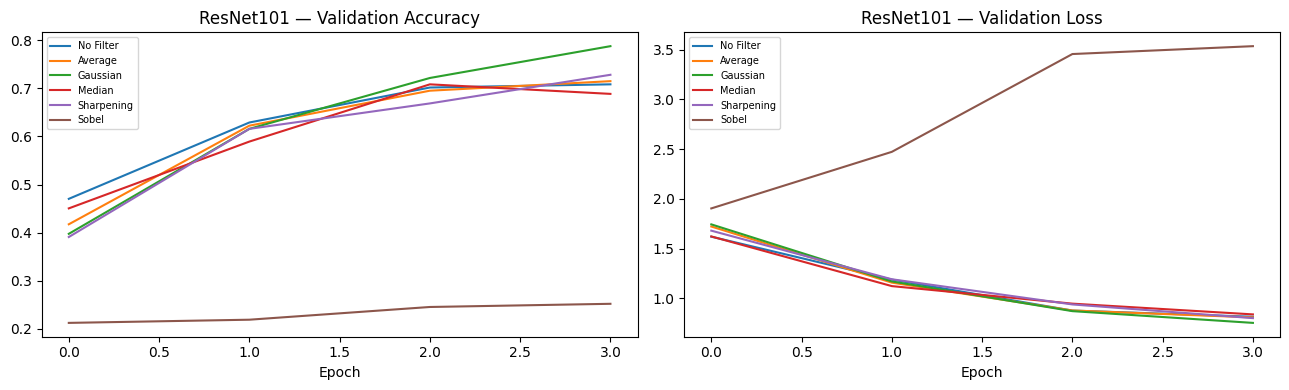

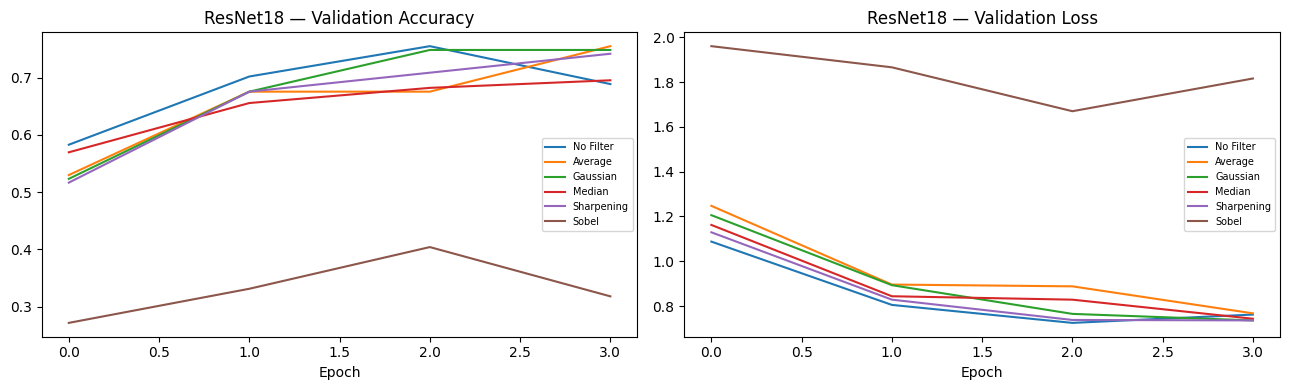

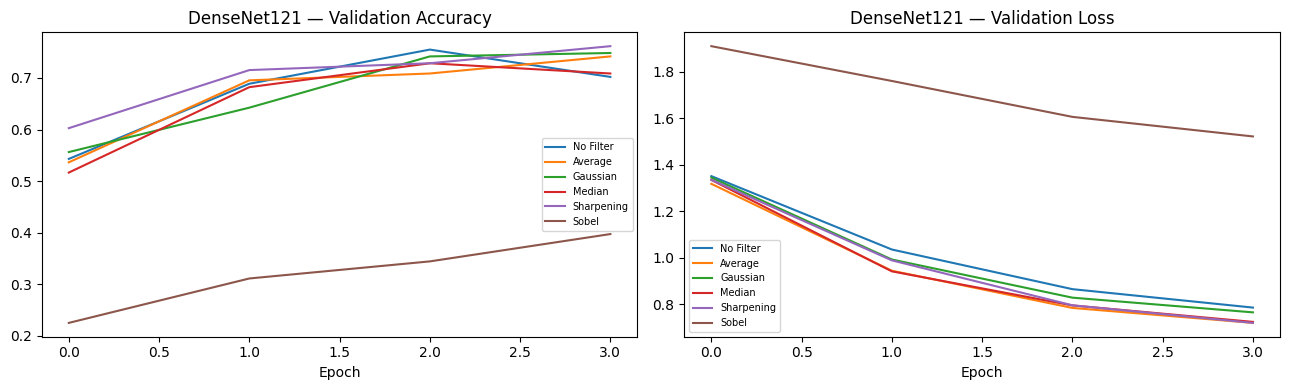

In [ ]:

for model_name in MODEL_NAMES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for filter_name in FILTER_NAMES:
        h = all_histories[(model_name, filter_name)]
        axes[0].plot(h["val_acc"], label=filter_name)
        axes[1].plot(h["val_loss"], label=filter_name)
    axes[0].set_title(f"{model_name} — Validation Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=7)
    axes[1].set_title(f"{model_name} — Validation Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(f"curves_{model_name}.png", dpi=150)
    plt.show()


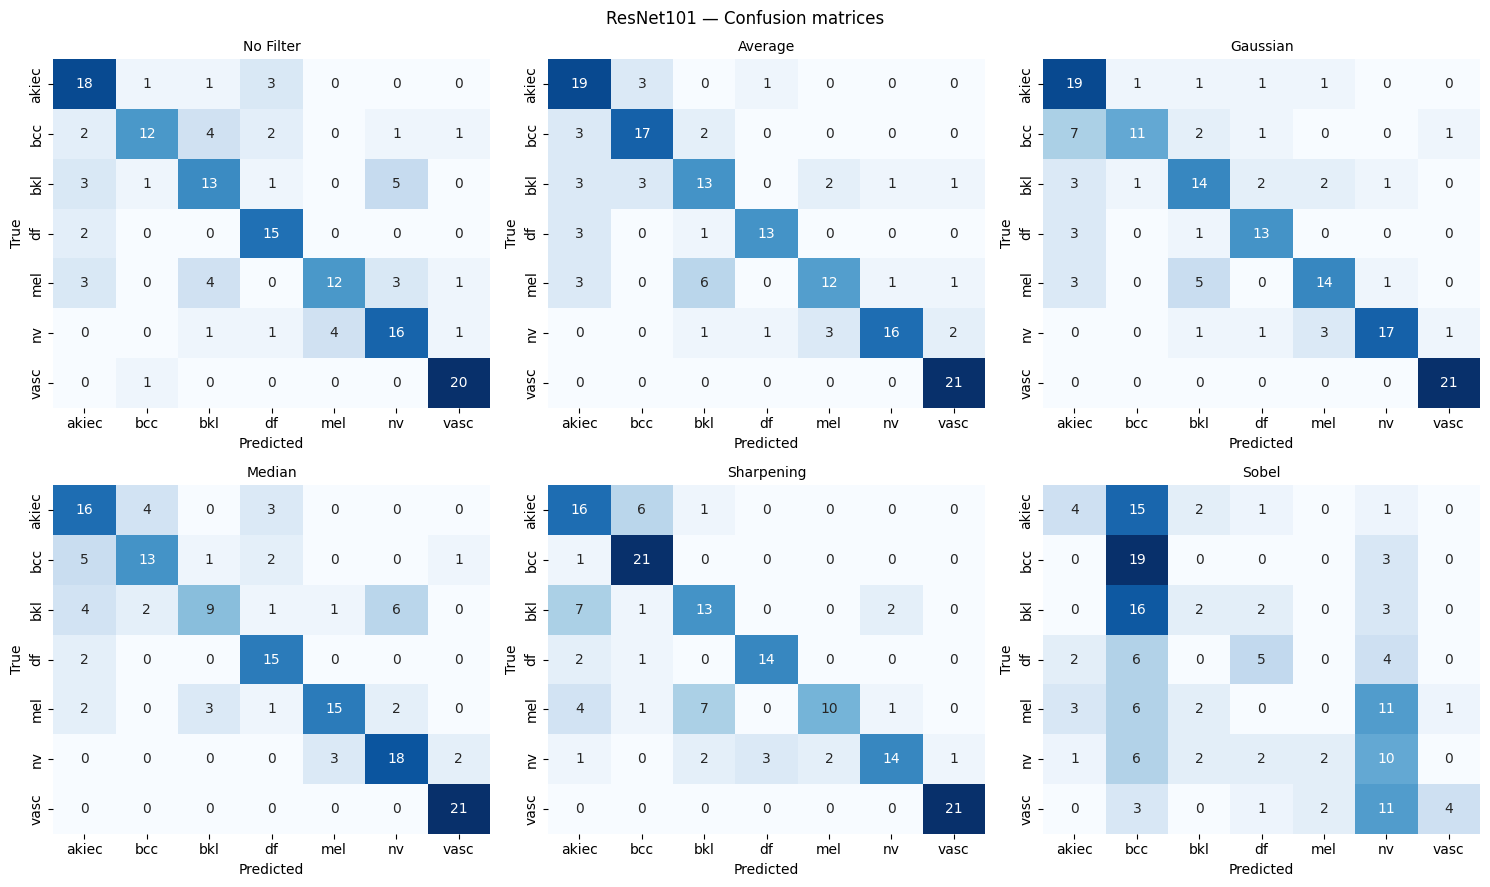

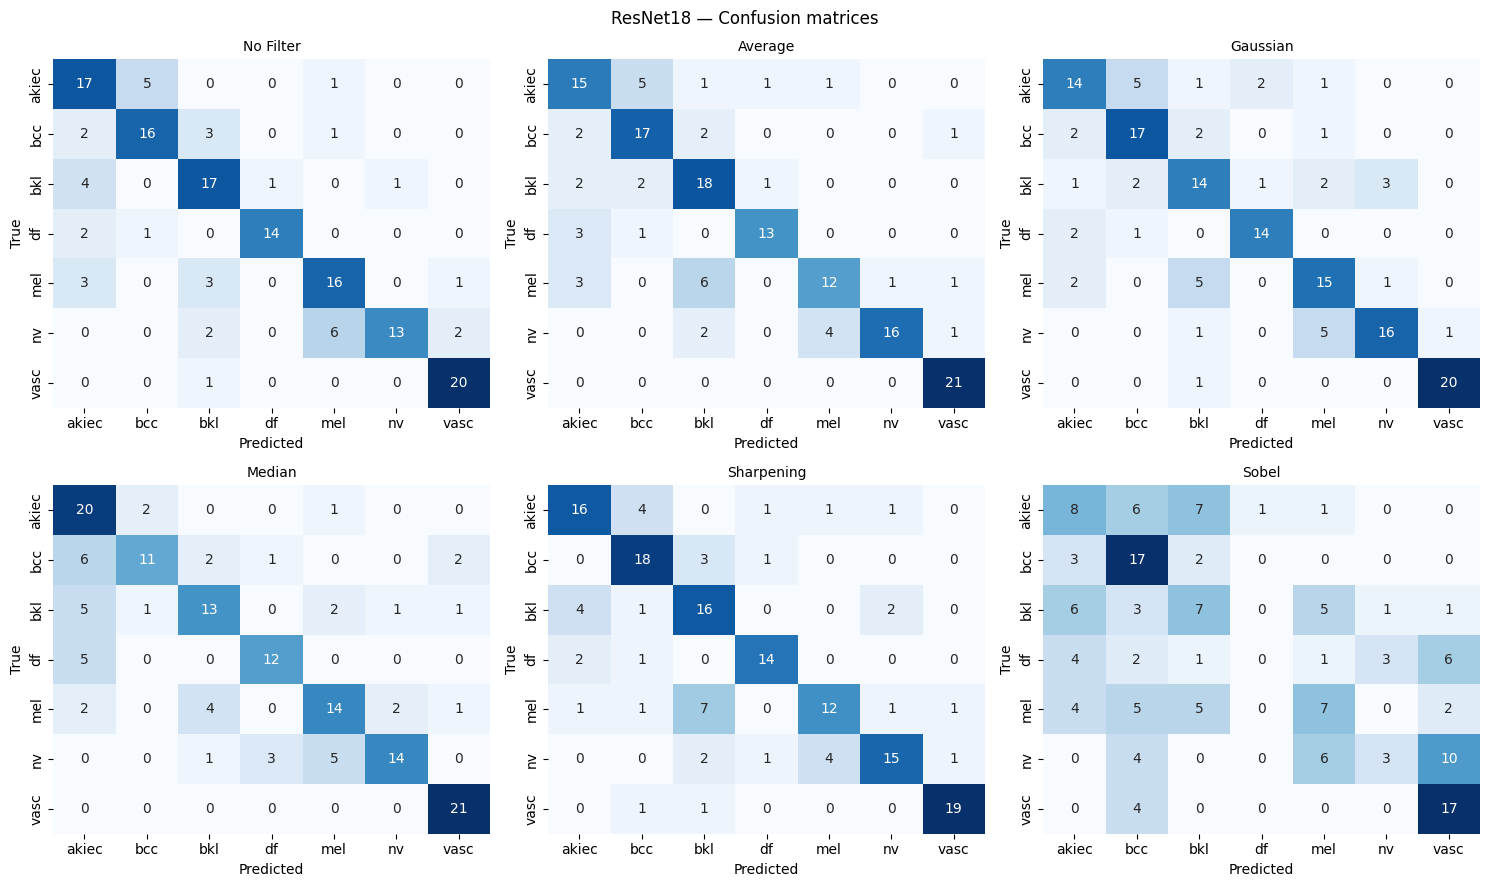

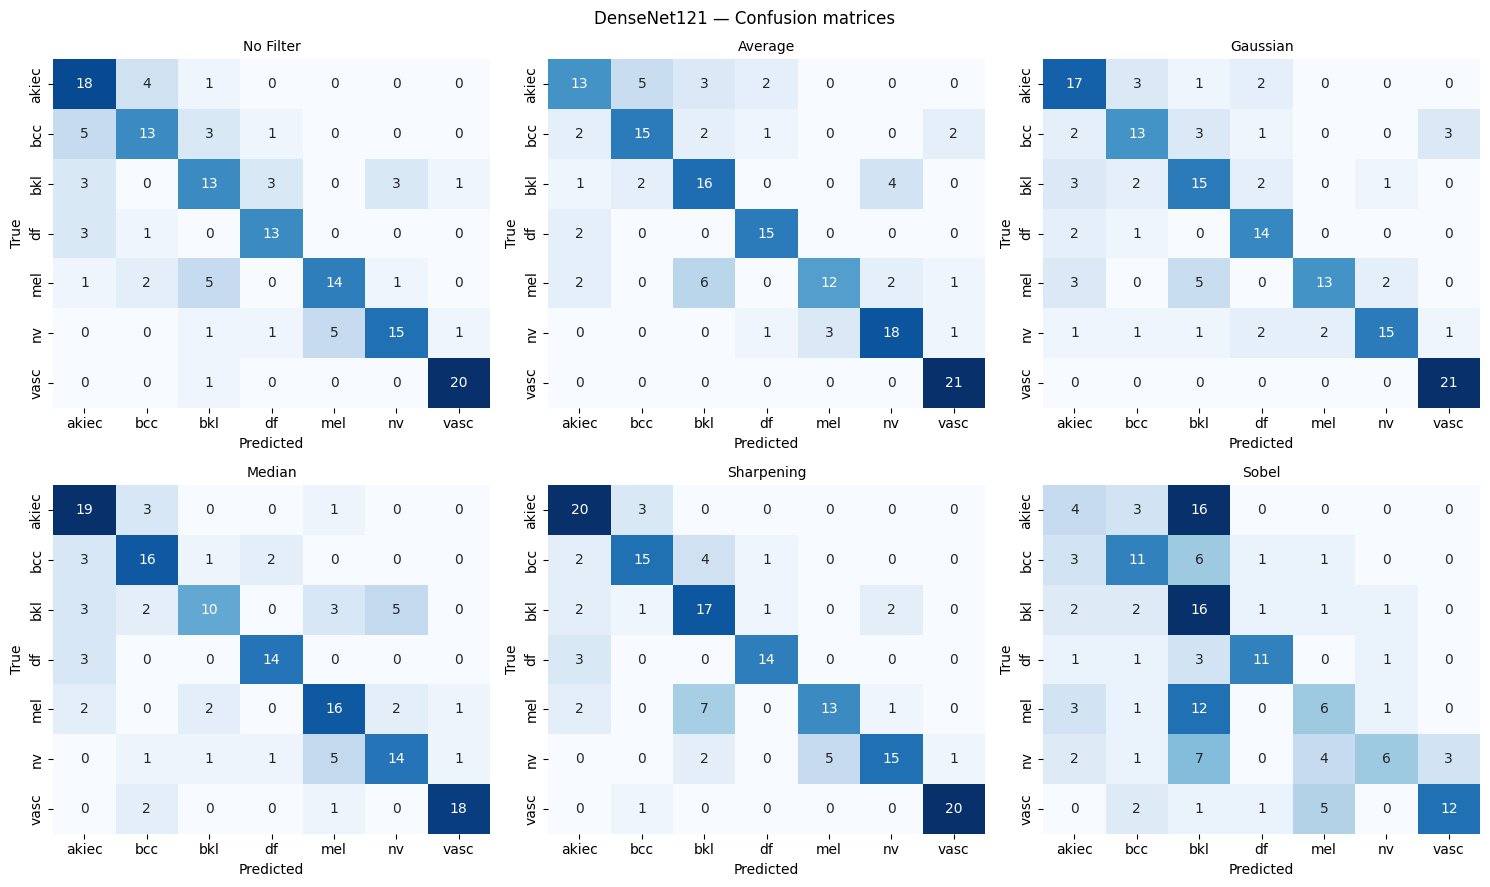

In [ ]:
# --- Confusion matrices: one grid per model (baseline + 5 filters) ---
for model_name in MODEL_NAMES:
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, filter_name in zip(axes.flat, FILTER_NAMES):
        cm = all_confusions[(model_name, filter_name)]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=CLASSES, yticklabels=CLASSES, cbar=False)
        ax.set_title(filter_name, fontsize=10)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    plt.suptitle(f"{model_name} — Confusion matrices")
    plt.tight_layout()
    plt.savefig(f"confusion_{model_name}.png", dpi=150)
    plt.show()


In [ ]:

for model_name in MODEL_NAMES:
    report = all_reports[(model_name, "No Filter")]
    per_class = pd.DataFrame(report).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]
    print(f"\n{model_name} — per-class metrics (No Filter baseline):")
    display(per_class.round(3))



ResNet101 — per-class metrics (No Filter baseline):


,precision,recall,f1-score,support
akiec,0.643,0.783,0.706,23.0
bcc,0.800,0.545,0.649,22.0
bkl,0.565,0.565,0.565,23.0
df,0.682,0.882,0.769,17.0
mel,0.750,0.522,0.615,23.0
nv,0.640,0.696,0.667,23.0
vasc,0.870,0.952,0.909,21.0



ResNet18 — per-class metrics (No Filter baseline):


,precision,recall,f1-score,support
akiec,0.607,0.739,0.667,23.0
bcc,0.727,0.727,0.727,22.0
bkl,0.654,0.739,0.694,23.0
df,0.933,0.824,0.875,17.0
mel,0.667,0.696,0.681,23.0
nv,0.929,0.565,0.703,23.0
vasc,0.870,0.952,0.909,21.0



DenseNet121 — per-class metrics (No Filter baseline):


,precision,recall,f1-score,support
akiec,0.600,0.783,0.679,23.0
bcc,0.650,0.591,0.619,22.0
bkl,0.542,0.565,0.553,23.0
df,0.722,0.765,0.743,17.0
mel,0.737,0.609,0.667,23.0
nv,0.789,0.652,0.714,23.0
vasc,0.909,0.952,0.930,21.0


## 11. Comparative analysis

The cells below compute, directly from `results_df`, the parts of the analysis that depend
on your actual numbers (deltas vs. baseline, most-affected filter/classes, whether the effect
is consistent across models). The theory questions (convolution vs. correlation, why
smoothing/sharpening help or hurt) are answered in the final markdown cell — read them
alongside your own numbers rather than as a substitute for them.


In [ ]:

baseline = results_df[results_df["Filter"] == "No Filter"].set_index("Model")
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score", "Macro-F1", "Balanced Accuracy", "AUC"]

delta_rows = []
for _, row in results_df.iterrows():
    base = baseline.loc[row["Model"]]
    delta_rows.append({
        "Model": row["Model"], "Filter": row["Filter"],
        **{f"Δ{m}": row[m] - base[m] for m in metric_cols}
    })
delta_df = pd.DataFrame(delta_rows)
delta_df.round(2)


,Model,Filter,ΔAccuracy,ΔPrecision,ΔRecall,ΔF1-score,ΔMacro-F1,ΔBalanced Accuracy,ΔAUC
0,ResNet101,No Filter,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,ResNet101,Average,3.29,3.85,2.87,3.58,3.58,2.87,1.51
2,ResNet101,Gaussian,1.97,3.61,1.46,2.25,2.25,1.46,0.67
3,ResNet101,Median,0.66,0.25,0.71,0.30,0.30,0.71,-1.12
4,ResNet101,Sharpening,1.97,3.81,1.96,2.24,2.24,1.96,0.72
5,ResNet101,Sobel,-40.79,-36.35,-41.45,-44.75,-44.75,-41.45,-28.49
6,ResNet18,No Filter,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,ResNet18,Average,-0.66,-1.39,-0.75,-0.98,-0.98,-0.75,-0.97
8,ResNet18,Gaussian,-1.97,-3.65,-1.84,-2.02,-2.02,-1.84,-0.43
9,ResNet18,Median,-5.26,-5.35,-5.49,-6.02,-6.02,-5.49,-0.21


In [ ]:

non_baseline = delta_df[delta_df["Filter"] != "No Filter"].copy()
non_baseline["abs_delta_macrof1"] = non_baseline["ΔMacro-F1"].abs()
greatest_change = non_baseline.loc[non_baseline.groupby("Model")["abs_delta_macrof1"].idxmax()]
print("Filter causing the greatest change vs. baseline, per model:")
greatest_change[["Model", "Filter", "ΔMacro-F1", "ΔAccuracy"]]


Filter causing the greatest change vs. baseline, per model:


,Model,Filter,ΔMacro-F1,ΔAccuracy
17,DenseNet121,Sobel,-25.015368,-26.315789
5,ResNet101,Sobel,-44.745675,-40.789474
11,ResNet18,Sobel,-42.132314,-35.526316


In [ ]:

consistency = (delta_df[delta_df["Filter"] != "No Filter"]
               .groupby("Filter")["ΔMacro-F1"]
               .apply(lambda s: "Consistent (same direction)" if (s > 0).all() or (s < 0).all()
                      else "Inconsistent across models"))
consistency


,ΔMacro-F1
Filter,
Average,Inconsistent across models
Gaussian,Inconsistent across models
Median,Inconsistent across models
Sharpening,Inconsistent across models
Sobel,Consistent (same direction)


In [ ]:

for model_name in MODEL_NAMES:
    base_report = all_reports[(model_name, "No Filter")]
    print(f"\n{model_name} — per-class F1 change (filter − baseline), averaged across all 5 filters:")
    diffs = {}
    for cls in CLASSES:
        base_f1 = base_report[cls]["f1-score"]
        deltas = [all_reports[(model_name, f)][cls]["f1-score"] - base_f1 for f in FILTER_NAMES if f != "No Filter"]
        diffs[cls] = np.mean(deltas)
    display(pd.Series(diffs, name="avg Δ F1-score").sort_values().round(3))



ResNet101 — per-class F1 change (filter − baseline), averaged across all 5 filters:


,avg Δ F1-score
akiec,-0.144
mel,-0.108
bkl,-0.094
vasc,-0.092
df,-0.068
bcc,-0.002
nv,-0.001



ResNet18 — per-class F1 change (filter − baseline), averaged across all 5 filters:


,avg Δ F1-score
df,-0.238
bkl,-0.130
mel,-0.124
akiec,-0.077
nv,-0.071
bcc,-0.058
vasc,-0.049



DenseNet121 — per-class F1 change (filter − baseline), averaged across all 5 filters:


,avg Δ F1-score
mel,-0.086
akiec,-0.086
nv,-0.066
vasc,-0.066
bkl,0.012
bcc,0.025
df,0.048


### Answers

**1. Which three pretrained models performed best in Lab Activity 1?**
ResNet101, ResNet18, and DenseNet121.

**6. (Data-driven — read together with the tables/plots above)**
Different filters change the performance of the three models in different ways.
Some filters improve performance, while others decrease it.
The filter with the biggest change is not always the same for every model.
Some skin-lesion classes are affected more than others.

**7. Why might smoothing remove useful lesion texture or morphological information?**
Mean, Gaussian, and Median filters make the image smoother and remove small details.
These details can include lesion texture, dots, patterns, and sharp borders.
Removing these details may make classification harder for the CNN.
Median filtering usually keeps edges better than Mean and Gaussian filters

**8. Why might sharpening or edge detection help or hurt classification?**
Sharpening makes edges and small details clearer, which may help classification.
However, it can also make noise and unwanted hair artifacts stronger.
Sobel mainly shows lesion edges but removes important color information.
Therefore, these filters can either improve or reduce model performance.

**9. What is the difference between convolution and correlation?**
Both methods move a filter over an image and calculate values from the pixels.
Convolution flips the filter, while correlation does not flip it.
For symmetric filters like Mean and Gaussian, the result is usually the same.
CNN Conv2d layers generally use correlation but are commonly called convolution.

**10. Relationship between classical image processing and deep-learning-based feature extraction.**
Classical filters (mean, Gaussian, median, sharpening, Sobel) are hand-designed, fixed
convolution kernels chosen by a human to extract one specific property (smoothness, edges,
etc.). The convolutional layers inside a CNN are the same mathematical operation, but the
Classical image filters such as Mean, Gaussian, Median, Sharpening, and Sobel are designed by humans to perform specific tasks, such as smoothing an image, removing noise, or detecting edges.

CNNs also use filters, but their filters are learned automatically from the training data.

A CNN can learn different types of features, such as:

Edges
Colors
Textures
Shapes
Complex patterns


In [ ]:
!jupyter nbconvert --to markdown "/content/CV_Lab02_041.ipynb"

[NbConvertApp] WARNING | pattern '/content/CV_Lab02_041.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--e